# Лабораторная работа 4: гибридный поиск в векторной базе Qdrant

### Задание

1. Развернуть векторную базу (например, https://qdrant.tech/).
2. Выбрать датасет (например, https://huggingface.co/datasets/mteb/fiqa) и инициализировать коллекцию.
3. Векторизовать документы семантической (например, вашей обученной) и лексической (например, BM25) моделями и загрузить их в коллекцию.
4. Настроить приемлемые скорость и качество поиска, подобрав их под конфигурацию машины.
5. Замерить качество гибридного поиска с шагом альфа 0.1. Множество запросов с разными альфа не нужно: фьюжн и расчёт можно выполнить вне векторной базы.


Запрос → E5 и BM25 → два списка из 100 кандидатов из Qdrant → нормализация оценок → взвешенная сумма для каждого α → метрики.

**Важное ограничение.** Модель из лабораторной 3 дообучалась на русскоязычном SberQuAD, а FiQA англоязычный. E5 многоязычная, поэтому работать на FiQA она может, но дообучения именно под финансовые английские тексты у неё не было. Это нужно учитывать при интерпретации результатов.

### Установка клиента Qdrant

Сервер Qdrant работает в контейнере, а из Python к нему обращается отдельная библиотека `qdrant-client`. Версия зафиксирована и совпадает с версией сервера, чтобы результат можно было воспроизвести.

In [1]:
%pip install -q "qdrant-client==1.20.0"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Библиотеки и общие настройки

Все параметры эксперимента собраны в одной ячейке:

- `MODEL_PATH` — путь к модели из лабораторной 3.
- `CANDIDATES = 100` — сколько кандидатов берём из каждого поиска. Этот список — единственное, из чего гибрид может собрать выдачу, поэтому он должен быть заметно длиннее десяти документов, по которым считается основная метрика.
- `ALPHAS` — значения α от 0.0 до 1.0 с шагом 0.1. Значения округлены, чтобы не получить в таблице 0.30000000000000004.
- `MIN_ANN_RECALL = 0.99` — наш критерий «приемлемого качества» приближённого поиска. Он выбран заранее, до замеров.
- Каталог `artifacts` хранит кэш эмбеддингов и не попадает в git, а `results` хранит таблицы и графики для отчёта.

In [2]:
import hashlib
import math
import os
import signal
import subprocess
import tarfile
import time
import urllib.request
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from qdrant_client import QdrantClient, models
from sentence_transformers import SentenceTransformer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Сервер Qdrant: готовая сборка для Linux с официальной страницы релизов
QDRANT_VERSION = "v1.20.0"
QDRANT_ARCHIVE = "qdrant-x86_64-unknown-linux-musl.tar.gz"
QDRANT_SHA256 = "b03a64616a1f41ddab78b480a318466541765f19835318113b1821cbea8df52c"
QDRANT_URL = "http://localhost:6333"

# Данные и модели
DATASET_NAME = "mteb/fiqa"
MODEL_PATH = "../lab3/qa/results"
BM25_MODEL = "qdrant/bm25"
COLLECTION = "fiqa_hybrid"

# Параметры эксперимента
CANDIDATES = 100
ALPHAS = [round(a * 0.1, 1) for a in range(11)]
MIN_ANN_RECALL = 0.99
EMBED_BATCH_SIZE = 64
UPLOAD_BATCH_SIZE = 256

# Каталоги для кэша и результатов
ARTIFACTS = Path("artifacts")
RESULTS = Path("results")
ARTIFACTS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

QDRANT_DIR = ARTIFACTS / "qdrant"
QDRANT_BINARY = QDRANT_DIR / "qdrant"
QDRANT_PID_FILE = QDRANT_DIR / "qdrant.pid"
QDRANT_DIR.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
for package in ("torch", "sentence-transformers", "qdrant-client"):
    print(package, version(package))

/home/lonaogoda/spailb/.venvconvlb/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cuda
GPU: NVIDIA GeForce RTX 3060
torch 2.14.1
sentence-transformers 6.2.0
qdrant-client 1.20.0


## 1. Развёртывание векторной базы

Qdrant запускается как отдельный процесс на этой же машине, контейнеры не нужны. Это настоящий сервер с индексом HNSW, а не встроенный режим клиента `QdrantClient(path=...)`: встроенный режим ищет полным перебором, и настраивать в нём скорость было бы нечего.

Что делает ячейка:

- **`download_qdrant`** скачивает готовую сборку с официальной страницы релизов, сверяет контрольную сумму SHA-256 с опубликованной и распаковывает архив в `artifacts/qdrant`. Если файл уже есть, повторно ничего не скачивается.
- **`ensure_qdrant`** запускает сервер, если он ещё не отвечает. Повторный запуск ячейки безопасен: второй сервер не появится.
- **`wait_for_qdrant`** ждёт готовности, потому что сразу после старта сервер ещё не принимает запросы.
- **`stop_qdrant`** останавливает сервер. Она вызывается в самом конце ноутбука и только вручную.

Настройки сервера передаются переменными окружения:

- `QDRANT__SERVICE__HOST=127.0.0.1` — сервер доступен только с этой машины.
- `QDRANT__STORAGE__STORAGE_PATH` — данные лежат в `artifacts/qdrant/storage` и переживают перезапуск сервера.
- `QDRANT__TELEMETRY_DISABLED=true` — отправка анонимной статистики отключена.

Сервер запускается в отдельной сессии (`start_new_session=True`), поэтому продолжает работать и после перезапуска ядра Jupyter. Его журнал пишется в `artifacts/qdrant/qdrant.log`.

In [3]:
def is_qdrant_ready():
    try:
        with urllib.request.urlopen(f"{QDRANT_URL}/readyz", timeout=2) as response:
            return response.status == 200
    except OSError:
        return False


def download_qdrant():
    if QDRANT_BINARY.exists():
        return

    archive_path = QDRANT_DIR / QDRANT_ARCHIVE
    url = f"https://github.com/qdrant/qdrant/releases/download/{QDRANT_VERSION}/{QDRANT_ARCHIVE}"
    print("Скачивание:", url)
    urllib.request.urlretrieve(url, archive_path)

    digest = hashlib.sha256(archive_path.read_bytes()).hexdigest()
    if digest != QDRANT_SHA256:
        archive_path.unlink()
        raise RuntimeError("Контрольная сумма архива не совпала.")

    with tarfile.open(archive_path) as archive:
        archive.extract("qdrant", path=QDRANT_DIR)
    archive_path.unlink()
    QDRANT_BINARY.chmod(0o755)
    print("Контрольная сумма совпала, сервер распакован.")


def ensure_qdrant():
    if is_qdrant_ready():
        print("Сервер уже работает.")
        return

    download_qdrant()

    environment = {
        **os.environ,
        "QDRANT__SERVICE__HOST": "127.0.0.1",
        "QDRANT__SERVICE__ENABLE_STATIC_CONTENT": "false",
        "QDRANT__STORAGE__STORAGE_PATH": str((QDRANT_DIR / "storage").resolve()),
        "QDRANT__STORAGE__SNAPSHOTS_PATH": str((QDRANT_DIR / "snapshots").resolve()),
        "QDRANT__TELEMETRY_DISABLED": "true",
    }
    with open(QDRANT_DIR / "qdrant.log", "ab") as log_file:
        process = subprocess.Popen(
            [str(QDRANT_BINARY.resolve())],
            cwd=QDRANT_DIR,
            env=environment,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )
    QDRANT_PID_FILE.write_text(str(process.pid))
    print("Сервер запущен, PID:", process.pid)


def wait_for_qdrant(timeout=60):
    deadline = time.time() + timeout
    while time.time() < deadline:
        if is_qdrant_ready():
            return
        time.sleep(1)
    raise TimeoutError("Qdrant не ответил вовремя. Журнал: artifacts/qdrant/qdrant.log")


def stop_qdrant():
    if not QDRANT_PID_FILE.exists():
        print("Файл с PID не найден.")
        return
    try:
        os.kill(int(QDRANT_PID_FILE.read_text()), signal.SIGTERM)
        print("Сервер остановлен.")
    except ProcessLookupError:
        print("Процесс уже завершён.")
    QDRANT_PID_FILE.unlink()


ensure_qdrant()
wait_for_qdrant()

client = QdrantClient(url=QDRANT_URL, timeout=300)
print("Версия сервера:", client.info().version)
print("Существующие коллекции:", [c.name for c in client.get_collections().collections])

Сервер запущен, PID: 3621
Версия сервера: 1.20.0
Существующие коллекции: ['fiqa_hybrid']


## 2. Выбор датасета и инициализация коллекции

### 2.1. Загрузка FiQA

Выбран [FiQA](https://huggingface.co/datasets/mteb/fiqa) из предложенного в задании. Это готовый набор для оценки поиска, и в нём есть всё необходимое:

- `corpus.jsonl` — документы, среди которых выполняется поиск;
- `queries.jsonl` — вопросы пользователей;
- `qrels/*.jsonl` — разметка: какие документы релевантны какому вопросу.

Используем две части разметки с разной ролью. **dev** нужен для настройки HNSW и выбора α, **test** — только для итоговой оценки. Если подбирать α и измерять качество на одних и тех же запросах, результат окажется завышенным. Часть `train` не нужна, потому что мы ничего не обучаем.

Типы столбцов заданы явно

In [4]:
def load_jsonl(filename, dtype):
    path = hf_hub_download(DATASET_NAME, filename, repo_type="dataset")
    return pd.read_json(path, lines=True, dtype=dtype)


corpus = load_jsonl("corpus.jsonl", {"_id": int, "title": str, "text": str})
queries = load_jsonl("queries.jsonl", {"_id": int, "text": str})
qrels_dev = load_jsonl("qrels/dev.jsonl", {"query-id": int, "corpus-id": int, "score": int})
qrels_test = load_jsonl("qrels/test.jsonl", {"query-id": int, "corpus-id": int, "score": int})

print("Документов:", len(corpus))
print("Запросов всего:", len(queries))
print("Dev: запросов", qrels_dev["query-id"].nunique(), "| пар", len(qrels_dev))
print("Test: запросов", qrels_test["query-id"].nunique(), "| пар", len(qrels_test))
print("\nПример запроса:", queries.iloc[0]["text"])
print("Пример документа:", corpus.iloc[0]["text"][:300])

Документов: 57638
Запросов всего: 6648
Dev: запросов 500 | пар 1238
Test: запросов 648 | пар 1706

Пример запроса: What is considered a business expense on a business trip?
Пример документа: I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange f


### 2.2. Проверка и подготовка данных

Прежде чем что-то загружать в базу, проверяем данные:

- нет ли пустых документов и повторяющихся идентификаторов;
- все ли размеченные документы есть в корпусе — иначе метрики были бы занижены;
- не пересекаются ли запросы dev и test — иначе нарушилась бы независимость итоговой оценки.

Здесь же считаем `AVG_DOC_LEN`, среднюю длину документа в словах. Это параметр формулы BM25: длинный документ не должен выигрывать только за счёт длины, а «длинность» определяется относительно среднего.

`relevance_by_query` превращает разметку в словарь «запрос → множество релевантных документов», с которым удобно считать метрики.

In [5]:
empty_docs = corpus["text"].str.strip().eq("").sum()
print("Пустых документов:", empty_docs)
print("Повторов _id в корпусе:", corpus["_id"].duplicated().sum())

word_counts = corpus["text"].str.split().str.len()
AVG_DOC_LEN = float(word_counts.mean())
print(f"Длина документа в словах: средняя {AVG_DOC_LEN:.1f}, медиана {word_counts.median():.0f}, максимум {word_counts.max()}")

corpus_ids = set(corpus["_id"])
assert set(qrels_dev["corpus-id"]) <= corpus_ids
assert set(qrels_test["corpus-id"]) <= corpus_ids
assert not set(qrels_dev["query-id"]) & set(qrels_test["query-id"])


def relevance_by_query(qrels):
    return (
        qrels[qrels["score"] > 0]
        .groupby("query-id")["corpus-id"]
        .apply(set)
        .to_dict()
    )


relevant_dev = relevance_by_query(qrels_dev)
relevant_test = relevance_by_query(qrels_test)

query_text = dict(zip(queries["_id"], queries["text"]))
dev_ids = sorted(relevant_dev)
test_ids = sorted(relevant_test)

print("Релевантных документов на запрос (test):", round(np.mean([len(v) for v in relevant_test.values()]), 2))

Пустых документов: 38
Повторов _id в корпусе: 0
Длина документа в словах: средняя 132.9, медиана 90, максимум 2973
Релевантных документов на запрос (test): 2.63


### 2.3. Инициализация коллекции

Коллекция Qdrant — это аналог таблицы. В одной точке (документе) можно хранить несколько именованных векторов, поэтому семантическое и лексическое представления лежат рядом:

- **`dense`** — плотный вектор E5 размерности 384. Сравнение идёт по косинусу, индекс — граф HNSW с параметрами `m` и `ef_construct`.
- **`bm25`** — разреженный вектор. `Modifier.IDF` означает, что статистику IDF считает сам Qdrant при поиске, и редкие слова весят больше частых.

Настройки оптимизатора заданы явно, и вот почему. По умолчанию Qdrant делит коллекцию на число сегментов, зависящее от числа ядер, а сегмент меньше порога индексации просматривается полным перебором. Наши 88 МБ плотных векторов на 16 ядрах могли бы оказаться у этого порога, и подбор HNSW потерял бы смысл. Поэтому задаём два сегмента (`default_segment_number=2`) и низкий порог (`indexing_threshold=1000` КБ), чтобы индекс гарантированно строился.

Функция `create_collection` также используется для временных коллекций при подборе параметров: там разреженный вектор не нужен.

In [6]:
def create_collection(name, m, ef_construct, with_bm25=True):
    if client.collection_exists(name):
        client.delete_collection(name)

    sparse_config = None
    if with_bm25:
        sparse_config = {"bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)}

    client.create_collection(
        collection_name=name,
        vectors_config={
            "dense": models.VectorParams(size=384, distance=models.Distance.COSINE)
        },
        sparse_vectors_config=sparse_config,
        hnsw_config=models.HnswConfigDiff(m=m, ef_construct=ef_construct),
        optimizers_config=models.OptimizersConfigDiff(
            default_segment_number=2,
            indexing_threshold=1000,
        ),
    )


# Начальные параметры: это значения Qdrant по умолчанию
DEFAULT_M = 16
DEFAULT_EF_CONSTRUCT = 100

create_collection(COLLECTION, DEFAULT_M, DEFAULT_EF_CONSTRUCT)
print(client.get_collection(COLLECTION).config.params)

vectors={'dense': VectorParams(size=384, distance=<Distance.COSINE: 'Cosine'>, hnsw_config=None, quantization_config=None, on_disk=None, memory=None, datatype=None, multivector_config=None)} shard_number=1 sharding_method=None replication_factor=1 write_consistency_factor=1 read_fan_out_factor=None read_fan_out_delay_ms=None on_disk_payload=True payload=None id_tracker=None sparse_vectors={'bm25': SparseVectorParams(index=None, modifier=<Modifier.IDF: 'idf'>)}


## 3. Векторизация и загрузка документов

### 3.1. Семантическая модель

Загружаем E5, дообученную в лабораторной 3. Модель обучалась с префиксами, и их нужно сохранить: `passage: ` перед документами и `query: ` перед запросами. Без них вход не соответствует формату E5.

Документы длиннее `max_seq_length` токенов обрезаются, поэтому печатаем это значение и долю таких документов (оценка по числу слов, токенов обычно ещё больше).

In [7]:
encoder = SentenceTransformer(MODEL_PATH, device=DEVICE)

print("Размерность:", encoder.get_sentence_embedding_dimension())
print("max_seq_length:", encoder.max_seq_length)
print("Документов длиннее этого числа слов:", f"{(word_counts > encoder.max_seq_length).mean():.2%}")


def encode_passages(texts):
    return encoder.encode(
        ["passage: " + text for text in texts],
        batch_size=EMBED_BATCH_SIZE,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )


def encode_queries(texts):
    return encoder.encode(
        ["query: " + text for text in texts],
        batch_size=EMBED_BATCH_SIZE,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1189.65it/s]


Размерность: 384
max_seq_length: 512
Документов длиннее этого числа слов: 2.02%


/tmp/ipykernel_1282/2333123053.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Размерность:", encoder.get_sentence_embedding_dimension())


### 3.2. Эмбеддинги документов и запросов

Эмбеддинги документов считаются один раз и сохраняются в `artifacts/corpus_e5.npy`. При повторном запуске ноутбука они читаются с диска. Проверка размера защищает от использования устаревшего файла.

Запросы dev и test кодируем заранее: при замерах скорости базы время работы модели учитываться не должно. Его измерим отдельно в части 5.

Векторы нормализованы до длины 1, что проверяет `assert`. Косинус таких векторов равен их скалярному произведению.

In [8]:
embeddings_path = ARTIFACTS / "corpus_e5.npy"

if embeddings_path.exists():
    corpus_embeddings = np.load(embeddings_path)
    print("Эмбеддинги загружены из кэша.")
else:
    start = time.perf_counter()
    corpus_embeddings = encode_passages(corpus["text"].tolist())
    elapsed = time.perf_counter() - start
    np.save(embeddings_path, corpus_embeddings)
    print(f"Векторизация заняла {elapsed:.1f} с ({len(corpus) / elapsed:.0f} документов/с).")

assert corpus_embeddings.shape == (len(corpus), 384)
assert np.allclose(np.linalg.norm(corpus_embeddings[:100], axis=1), 1.0, atol=1e-3)

dev_embeddings = encode_queries([query_text[q] for q in dev_ids])
test_embeddings = encode_queries([query_text[q] for q in test_ids])

print("Матрица документов:", corpus_embeddings.shape)
print("Запросы dev / test:", dev_embeddings.shape, test_embeddings.shape)

Эмбеддинги загружены из кэша.
Матрица документов: (57638, 384)
Запросы dev / test: (500, 384) (648, 384)


### 3.3. Лексическая модель и загрузка в коллекцию

Для лексической части используем BM25. Вектор передаётся как объект `models.Document`: мы отправляем текст, а Qdrant сам разбивает его на слова, приводит к основам (стемминг), убирает стоп-слова и строит разреженный вектор. Параметры задаём словарём `BM25_OPTIONS`; те же настройки нужны и для запросов.

Функция `upload_points` загружает данные пакетами, чтобы не отправлять весь корпус одним запросом. Идентификатор точки равен идентификатору документа в FiQA, поэтому результаты поиска напрямую сопоставляются с разметкой. В основной коллекции текст сохраняется в `payload`, чтобы его можно было показать в выдаче.

Индекс HNSW строится в фоне и после окончания загрузки. Функция `wait_until_indexed` ждёт, пока коллекция станет зелёной и оптимизатор закончит работу: иначе скорость измерялась бы на недостроенном индексе.

In [9]:
BM25_OPTIONS = {"avg_len": AVG_DOC_LEN, "language": "english"}


def bm25_document(text):
    return models.Document(text=text, model=BM25_MODEL, options=BM25_OPTIONS)


def upload_points(name, with_bm25=True):
    doc_ids = corpus["_id"].tolist()
    texts = corpus["text"].tolist()

    for start in range(0, len(doc_ids), UPLOAD_BATCH_SIZE):
        points = []
        for i in range(start, min(start + UPLOAD_BATCH_SIZE, len(doc_ids))):
            vector = {"dense": corpus_embeddings[i].tolist()}
            payload = None
            if with_bm25:
                vector["bm25"] = bm25_document(texts[i])
                payload = {"text": texts[i]}
            points.append(models.PointStruct(id=doc_ids[i], vector=vector, payload=payload))
        client.upsert(collection_name=name, points=points, wait=True)


def wait_until_indexed(name, timeout=1800):
    deadline = time.time() + timeout
    time.sleep(2)  # даём оптимизатору начать работу
    green_in_a_row = 0
    while time.time() < deadline:
        info = client.get_collection(name)
        if info.status == models.CollectionStatus.GREEN:
            green_in_a_row += 1
            if green_in_a_row >= 3:
                return info
        else:
            green_in_a_row = 0
        time.sleep(1)
    raise TimeoutError(f"Индекс коллекции {name} не построен вовремя.")


def build_main_collection(m, ef_construct):
    create_collection(COLLECTION, m, ef_construct)
    start = time.perf_counter()
    upload_points(COLLECTION)
    uploaded = time.perf_counter() - start
    info = wait_until_indexed(COLLECTION)
    total = time.perf_counter() - start

    assert client.count(COLLECTION, exact=True).count == len(corpus)
    print(f"m={m}, ef_construct={ef_construct}")
    print(f"Загрузка: {uploaded:.1f} с | вместе с индексом: {total:.1f} с")
    print("Точек:", info.points_count, "| сегментов:", info.segments_count, "| статус:", info.status.value)
    print("Проиндексировано векторов:", info.indexed_vectors_count)


build_main_collection(DEFAULT_M, DEFAULT_EF_CONSTRUCT)

m=16, ef_construct=100
Загрузка: 28.4 с | вместе с индексом: 32.5 с
Точек: 57638 | сегментов: 2 | статус: green
Проиндексировано векторов: 115236


### 3.4. Проверка поиска

Прежде чем что-либо измерять, смотрим на один запрос глазами: оба вида поиска должны возвращать осмысленные документы. Метод `query_points` с параметром `using` выбирает, по какому вектору искать. Оценки двух моделей имеют разную шкалу: у косинуса значения не больше 1, у BM25 они не ограничены сверху. Именно поэтому в части 5 оценки придётся нормализовать.

In [10]:
sample_query_id = test_ids[0]
sample_query = query_text[sample_query_id]
print("Запрос:", sample_query)

dense_sample = client.query_points(
    COLLECTION,
    query=encode_queries([sample_query])[0].tolist(),
    using="dense",
    limit=3,
    with_payload=True,
).points

bm25_sample = client.query_points(
    COLLECTION,
    query=bm25_document(sample_query),
    using="bm25",
    limit=3,
    with_payload=True,
).points

for title, points in (("E5", dense_sample), ("BM25", bm25_sample)):
    print(f"\n{title}:")
    for point in points:
        mark = "релевантен" if point.id in relevant_test[sample_query_id] else "нет в разметке"
        print(f"  {point.score:.3f} [{mark}] {point.payload['text'][:160]}")

Запрос: How to deposit a cheque issued to an associate in my business into my business account?

E5:
  0.748 [релевантен] Just have the associate sign the back and then deposit it.  It's called a third party cheque and is perfectly legal.  I wouldn't be surprised if it has a longer
  0.744 [нет в разметке] "Depending on how the check was made out, you may be able to file a DBA (""doing business as""), which would give you the business name locally.  Then open an a
  0.734 [нет в разметке] Assuming it's your business, endorse the check as yourself and your DBA name, payable to your personal account

BM25:
  30.559 [релевантен] Just have the associate sign the back and then deposit it.  It's called a third party cheque and is perfectly legal.  I wouldn't be surprised if it has a longer
  23.130 [нет в разметке] So does a post-dated check have any valid use in a business or   personal transaction? Does it provide any financial or legal   protections at all? Yes, most de
  21.451 [нет в ра

## 4. Настройка скорости и качества поиска

### 4.1. Метрики качества

Метрики реализованы вручную: для бинарной разметки они короткие, а каждый шаг виден.

- **nDCG@10** — основная метрика. Учитывает, на каких местах первой десятки стоят релевантные документы, и нормируется на идеальную выдачу.
- **Recall@10** и **Recall@100** — какая доля релевантных документов попала в первые 10 и 100 результатов.
- **MRR@10** — обратный ранг первого релевантного документа.

Функции нужны уже при настройке HNSW, поэтому определены здесь. `assert` проверяют их на маленьком примере с заранее посчитанным вручную ответом: единственный релевантный документ на втором месте даёт nDCG = 1 / log₂3 ≈ 0.6309 и MRR = 0.5.

In [11]:
def dcg_ideal(n_relevant, k):
    return sum(1.0 / math.log2(rank + 2) for rank in range(min(n_relevant, k)))


def ndcg_at_k(ranking, relevant, k=10):
    dcg = sum(
        1.0 / math.log2(rank + 2)
        for rank, doc_id in enumerate(ranking[:k])
        if doc_id in relevant
    )
    return dcg / dcg_ideal(len(relevant), k)


def recall_at_k(ranking, relevant, k):
    return len(set(ranking[:k]) & relevant) / len(relevant)


def mrr_at_k(ranking, relevant, k=10):
    for rank, doc_id in enumerate(ranking[:k]):
        if doc_id in relevant:
            return 1.0 / (rank + 1)
    return 0.0


def per_query_metrics(rankings, relevant_by_query):
    rows = []
    for query_id, relevant in relevant_by_query.items():
        ranking = rankings[query_id]
        rows.append({
            "query_id": query_id,
            "nDCG@10": ndcg_at_k(ranking, relevant),
            "Recall@10": recall_at_k(ranking, relevant, 10),
            "Recall@100": recall_at_k(ranking, relevant, 100),
            "MRR@10": mrr_at_k(ranking, relevant),
        })
    return pd.DataFrame(rows).set_index("query_id")


# Проверка на примере, посчитанном вручную
assert abs(ndcg_at_k([1, 2, 3], {2}) - 1 / math.log2(3)) < 1e-9
assert ndcg_at_k([2, 1], {2}) == 1.0
assert ndcg_at_k([1, 3], {2}) == 0.0
assert mrr_at_k([1, 2, 3], {2}) == 0.5
assert recall_at_k([1, 2, 3], {2, 9}, 10) == 0.5
print("Функции метрик прошли проверку.")

Функции метрик прошли проверку.


### 4.2. Что настраиваем и как измеряем

HNSW — это приближённый поиск по графу. Он быстрее полного перебора, но может пропустить часть ближайших соседей. На баланс скорости и точности влияют три параметра:

- `m` — число связей у вершины графа. Больше связей — выше точность, но больше памяти и дольше построение.
- `ef_construct` — ширина поиска при построении графа. Больше значение — качественнее граф, дольше построение.
- `hnsw_ef` — ширина поиска при запросе. Больше значение — точнее и медленнее. Этот параметр меняется без перестройки индекса.

**Эталон** — точный поиск (`exact=True`), полный перебор всех векторов. **ANN Recall@100** показывает, какая доля точных 100 соседей нашлась через HNSW. Смотрим именно на 100, потому что столько кандидатов получает гибрид.

**Скорость** измеряем последовательными запросами на dev. В замер входит и сетевой обмен с клиентом, так как именно это время увидит приложение. Кроме средней задержки считаем 95-й перцентиль (p95): он показывает, сколько ждут самые медленные запросы. Первые запросы прогревают кэши и в замер не входят.

In [12]:
dev_vectors = [vector.tolist() for vector in dev_embeddings]


def timed_dense_search(name, vectors, search_params, limit=CANDIDATES):
    # Прогрев: первые запросы медленнее из-за холодных кэшей
    for vector in vectors[:30]:
        client.query_points(name, query=vector, using="dense", limit=limit,
                            search_params=search_params, with_payload=False)

    latencies = []
    results = []
    for vector in vectors:
        start = time.perf_counter()
        response = client.query_points(name, query=vector, using="dense", limit=limit,
                                       search_params=search_params, with_payload=False)
        latencies.append((time.perf_counter() - start) * 1000)
        results.append([point.id for point in response.points])
    return results, np.array(latencies)


exact_results, exact_latency = timed_dense_search(
    COLLECTION, dev_vectors, models.SearchParams(exact=True)
)
exact_sets = [set(ids) for ids in exact_results]

print(f"Точный поиск: среднее {exact_latency.mean():.2f} мс, p95 {np.percentile(exact_latency, 95):.2f} мс")

Точный поиск: среднее 5.80 мс, p95 6.54 мс


### 4.3. Перебор параметров

Берём три конфигурации графа: более лёгкую, значения по умолчанию и более плотную. Для каждой строим временную коллекцию только с плотными векторами, засекаем время построения и перебираем `hnsw_ef`. Значения `hnsw_ef` начинаются со 100, потому что запрашиваем 100 кандидатов и меньшая ширина поиска не имеет смысла.

В таблицу также попадает nDCG@10 по разметке dev: это показывает, сказывается ли приближённость поиска на качестве, которое видит пользователь. Временные коллекции удаляются сразу после замеров.

In [13]:
HNSW_CONFIGS = [(8, 64), (16, 100), (32, 200)]
EF_VALUES = [100, 128, 200, 300, 500]
TUNING_COLLECTION = "fiqa_tuning"

tuning_rows = []

for m, ef_construct in HNSW_CONFIGS:
    create_collection(TUNING_COLLECTION, m, ef_construct, with_bm25=False)
    start = time.perf_counter()
    upload_points(TUNING_COLLECTION, with_bm25=False)
    info = wait_until_indexed(TUNING_COLLECTION)
    build_seconds = time.perf_counter() - start
    print(f"m={m}, ef_construct={ef_construct}: построено за {build_seconds:.1f} с, "
          f"проиндексировано {info.indexed_vectors_count}")

    for ef in EF_VALUES:
        results, latency = timed_dense_search(
            TUNING_COLLECTION, dev_vectors, models.SearchParams(hnsw_ef=ef)
        )
        ann_recall = np.mean([
            len(set(found) & truth) / len(truth)
            for found, truth in zip(results, exact_sets)
        ])
        rankings = dict(zip(dev_ids, results))
        tuning_rows.append({
            "m": m,
            "ef_construct": ef_construct,
            "hnsw_ef": ef,
            "build_s": round(build_seconds, 1),
            "ANN_Recall@100": round(float(ann_recall), 4),
            "nDCG@10_dev": round(per_query_metrics(rankings, relevant_dev)["nDCG@10"].mean(), 4),
            "mean_ms": round(float(latency.mean()), 2),
            "p95_ms": round(float(np.percentile(latency, 95)), 2),
            "QPS": round(1000 / float(latency.mean()), 1),
        })

client.delete_collection(TUNING_COLLECTION)

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.to_csv(RESULTS / "hnsw_tuning.csv", index=False)
display(tuning_df)
print(f"Для сравнения, точный поиск: среднее {exact_latency.mean():.2f} мс, p95 {np.percentile(exact_latency, 95):.2f} мс")

m=8, ef_construct=64: построено за 11.8 с, проиндексировано 57638
m=16, ef_construct=100: построено за 12.3 с, проиндексировано 57638
m=32, ef_construct=200: построено за 15.6 с, проиндексировано 57638


,m,ef_construct,hnsw_ef,build_s,ANN_Recall@100,nDCG@10_dev,mean_ms,p95_ms,QPS
0,8,64,100,11.8,0.7748,0.2948,2.21,2.51,452.4
1,8,64,128,11.8,0.8127,0.2979,2.28,2.67,437.7
2,8,64,200,11.8,0.8676,0.3033,2.33,2.59,430.0
3,8,64,300,11.8,0.9054,0.3053,2.65,3.33,377.6
4,8,64,500,11.8,0.9379,0.3136,2.68,3.07,372.6
5,16,100,100,12.3,0.8695,0.3047,2.25,2.56,443.5
6,16,100,128,12.3,0.8997,0.3086,2.26,2.50,442.5
7,16,100,200,12.3,0.9393,0.3159,2.45,2.73,408.4
8,16,100,300,12.3,0.9625,0.3205,2.63,2.97,380.4
9,16,100,500,12.3,0.9797,0.3249,3.01,3.48,331.7


Для сравнения, точный поиск: среднее 5.80 мс, p95 6.54 мс


### 4.4. Общий стиль графиков и компромисс скорости и точности

На графике каждая линия — конфигурация графа HNSW, каждая точка — значение `hnsw_ef`. Лучшие точки находятся слева вверху: быстро и точно. Пунктир отмечает порог ANN Recall@100 = 0.99.

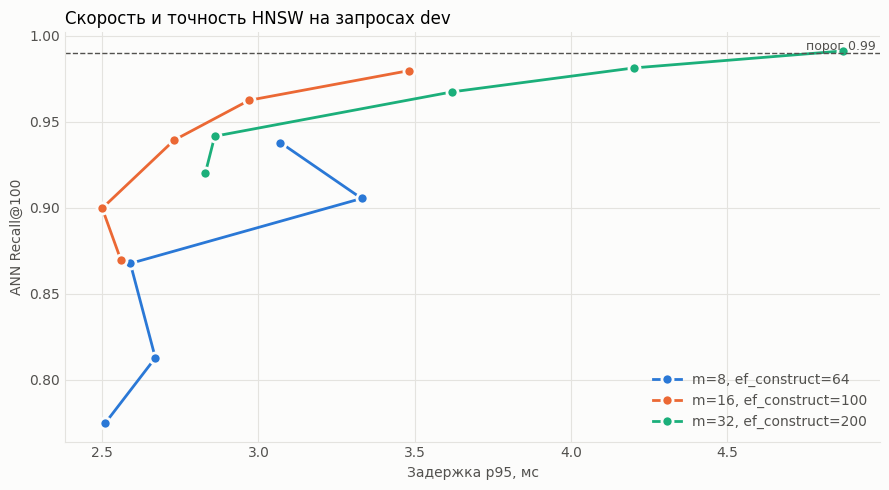

In [14]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e4e3df"


def style_axes(ax):
    ax.figure.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)
    ax.xaxis.label.set_color(INK_MUTED)
    ax.yaxis.label.set_color(INK_MUTED)
    ax.title.set_color(INK)
    ax.set_axisbelow(True)
    ax.grid(color=GRID, linewidth=0.8)


fig, ax = plt.subplots(figsize=(9, 5))

for color, (m, ef_construct) in zip(COLORS, HNSW_CONFIGS):
    rows = tuning_df[tuning_df["m"] == m].sort_values("hnsw_ef")
    ax.plot(rows["p95_ms"], rows["ANN_Recall@100"], color=color, linewidth=2, marker="o",
            markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
            label=f"m={m}, ef_construct={ef_construct}")

ax.axhline(MIN_ANN_RECALL, color=INK_MUTED, linewidth=1, linestyle="--")
ax.text(ax.get_xlim()[1], MIN_ANN_RECALL, f"порог {MIN_ANN_RECALL} ", color=INK_MUTED,
        ha="right", va="bottom", fontsize=9)
ax.set_xlabel("Задержка p95, мс")
ax.set_ylabel("ANN Recall@100")
ax.set_title("Скорость и точность HNSW на запросах dev", loc="left")
ax.legend(frameon=False, loc="lower right", labelcolor=INK_MUTED)
style_axes(ax)
fig.tight_layout()
fig.savefig(RESULTS / "hnsw_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5. Выбор параметров

Правило выбора зафиксировано заранее: среди конфигураций с ANN Recall@100 не ниже `MIN_ANN_RECALL` берём самую быструю по p95. При равенстве предпочитаем меньшие `hnsw_ef` и `m`. Если порог не достигнут нигде, берём самую точную конфигурацию.

Если выбранный граф отличается от начального, основная коллекция пересоздаётся с новыми параметрами. Значение `hnsw_ef` в индекс не входит, его передаём с каждым запросом. В конце проверяем, что итоговая коллекция действительно обеспечивает нужную точность.

In [15]:
acceptable = tuning_df[tuning_df["ANN_Recall@100"] >= MIN_ANN_RECALL]

if len(acceptable):
    best_row = acceptable.sort_values(["p95_ms", "hnsw_ef", "m"]).iloc[0]
else:
    print("Порог не достигнут, берём самую точную конфигурацию.")
    best_row = tuning_df.sort_values("ANN_Recall@100", ascending=False).iloc[0]

BEST_M = int(best_row["m"])
BEST_EF_CONSTRUCT = int(best_row["ef_construct"])
BEST_EF = int(best_row["hnsw_ef"])
SEARCH_PARAMS = models.SearchParams(hnsw_ef=BEST_EF)

print(f"Выбрано: m={BEST_M}, ef_construct={BEST_EF_CONSTRUCT}, hnsw_ef={BEST_EF}")

if (BEST_M, BEST_EF_CONSTRUCT) != (DEFAULT_M, DEFAULT_EF_CONSTRUCT):
    build_main_collection(BEST_M, BEST_EF_CONSTRUCT)
else:
    print("Граф совпадает с начальным, пересоздавать коллекцию не нужно.")

final_results, final_latency = timed_dense_search(COLLECTION, dev_vectors, SEARCH_PARAMS)
final_recall = np.mean([
    len(set(found) & truth) / len(truth)
    for found, truth in zip(final_results, exact_sets)
])
print(f"Итоговая коллекция: ANN Recall@100 = {final_recall:.4f}, "
      f"среднее {final_latency.mean():.2f} мс, p95 {np.percentile(final_latency, 95):.2f} мс")

Выбрано: m=32, ef_construct=200, hnsw_ef=500
m=32, ef_construct=200
Загрузка: 29.7 с | вместе с индексом: 34.8 с
Точек: 57638 | сегментов: 2 | статус: green
Проиндексировано векторов: 115236
Итоговая коллекция: ANN Recall@100 = 0.9918, среднее 3.82 мс, p95 4.65 мс


## 5. Качество гибридного поиска

### 5.1. Получение кандидатов из базы

Задание разрешает не делать отдельные запросы для каждого α, и в этом нет необходимости. Для каждого запроса один раз получаем два списка из `CANDIDATES` документов с оценками, а дальше работаем с ними в Python.

`query_batch_points` отправляет запросы пакетом, что быстрее, чем по одному. `retrieve_candidates` возвращает словарь: запрос `{документ: оценка}`.

In [17]:
def retrieve_candidates(query_ids, embeddings, batch_size=64):
    dense_hits = {}
    bm25_hits = {}

    for start in range(0, len(query_ids), batch_size):
        batch_ids = query_ids[start:start + batch_size]
        batch_vectors = embeddings[start:start + batch_size]

        dense_requests = [
            models.QueryRequest(query=vector.tolist(), using="dense", limit=CANDIDATES,
                                params=SEARCH_PARAMS, with_payload=False)
            for vector in batch_vectors
        ]
        bm25_requests = [
            models.QueryRequest(query=bm25_document(query_text[q]), using="bm25",
                                limit=CANDIDATES, with_payload=False)
            for q in batch_ids
        ]

        dense_responses = client.query_batch_points(COLLECTION, requests=dense_requests)
        bm25_responses = client.query_batch_points(COLLECTION, requests=bm25_requests)

        for q, dense, bm25 in zip(batch_ids, dense_responses, bm25_responses):
            dense_hits[q] = {point.id: point.score for point in dense.points}
            bm25_hits[q] = {point.id: point.score for point in bm25.points}

    return dense_hits, bm25_hits


dense_dev, bm25_dev = retrieve_candidates(dev_ids, dev_embeddings)
dense_test, bm25_test = retrieve_candidates(test_ids, test_embeddings)

print("Запросов без результатов BM25 (dev / test):",
      sum(not hits for hits in bm25_dev.values()), "/",
      sum(not hits for hits in bm25_test.values()))
print("Среднее число уникальных кандидатов на запрос (test):",
      round(np.mean([len(set(dense_test[q]) | set(bm25_test[q])) for q in test_ids]), 1))

Запросов без результатов BM25 (dev / test): 0 / 0
Среднее число уникальных кандидатов на запрос (test): 175.5


### 5.2. Фьюжн вне базы

Оценки E5 и BM25 находятся в разных шкалах, поэтому складывать их напрямую нельзя: BM25 подавил бы косинус. Сначала для каждого запроса приводим оценки каждой модели к диапазону [0, 1] (min-max нормализация), затем считаем:

$$\text{score}(d) = \alpha \cdot \text{dense}(d) + (1 - \alpha) \cdot \text{bm25}(d)$$

- **α = 0** — только BM25, **α = 1** — только E5, промежуточные значения — гибрид.
- Если документа нет в списке одной из моделей, его оценка по ней равна 0, то есть он приравнивается к худшему кандидату этого списка.
- Если в списке один документ или все оценки равны, диапазона нет и все они получают 1.
- Сортировка идёт по убыванию оценки, а при равенстве по идентификатору документа, чтобы результат был детерминированным.

Краевые случаи проверены: при α = 1 порядок должен совпасть с порядком E5, при α = 0 — с BM25. Это проверка того, что фьюжн не искажает исходные выдачи.

In [18]:
def minmax_normalize(hits):
    if not hits:
        return {}
    values = hits.values()
    low, high = min(values), max(values)
    if high == low:
        return {doc_id: 1.0 for doc_id in hits}
    return {doc_id: (score - low) / (high - low) for doc_id, score in hits.items()}


def fuse(dense_hits, bm25_hits, alpha, limit=CANDIDATES):
    dense_norm = minmax_normalize(dense_hits)
    bm25_norm = minmax_normalize(bm25_hits)

    # При крайних alpha кандидаты другой модели не должны попадать в выдачу
    if alpha == 1.0:
        candidates = set(dense_norm)
    elif alpha == 0.0:
        candidates = set(bm25_norm)
    else:
        candidates = set(dense_norm) | set(bm25_norm)

    scored = [
        (alpha * dense_norm.get(doc_id, 0.0) + (1 - alpha) * bm25_norm.get(doc_id, 0.0), doc_id)
        for doc_id in candidates
    ]
    scored.sort(key=lambda item: (-item[0], item[1]))
    return [doc_id for _, doc_id in scored[:limit]]


def evaluate_alphas(dense_hits, bm25_hits, relevant):
    per_alpha = {}
    for alpha in ALPHAS:
        rankings = {q: fuse(dense_hits[q], bm25_hits[q], alpha) for q in relevant}
        per_alpha[alpha] = per_query_metrics(rankings, relevant)
    return per_alpha


def by_score(hits):
    return [doc_id for doc_id, _ in sorted(hits.items(), key=lambda item: (-item[1], item[0]))]


# Крайние значения alpha должны воспроизводить исходные выдачи
for q in dev_ids[:50]:
    assert fuse(dense_dev[q], bm25_dev[q], 1.0) == by_score(dense_dev[q])
    assert fuse(dense_dev[q], bm25_dev[q], 0.0) == by_score(bm25_dev[q])
print("Проверка крайних значений alpha пройдена.")

Проверка крайних значений alpha пройдена.


### 5.3. Замер качества на dev и выбор α

Считаем все метрики для одиннадцати значений α на запросах dev. Лучшим считаем α с максимальным nDCG@10. Test на этом шаге не используется вообще.

In [19]:
metrics_dev = evaluate_alphas(dense_dev, bm25_dev, relevant_dev)

alpha_dev = pd.DataFrame({alpha: frame.mean() for alpha, frame in metrics_dev.items()}).T
alpha_dev.index.name = "alpha"
alpha_dev.round(4).to_csv(RESULTS / "hybrid_alpha_dev.csv")

BEST_ALPHA = float(alpha_dev["nDCG@10"].idxmax())
print("Лучшее alpha на dev:", BEST_ALPHA)
display(alpha_dev.round(4))

Лучшее alpha на dev: 0.5


,nDCG@10,Recall@10,Recall@100,MRR@10
alpha,,,,
0.0,0.2699,0.3271,0.5460,0.3317
0.1,0.2901,0.3453,0.6307,0.3584
0.2,0.3047,0.3582,0.6404,0.3759
0.3,0.3222,0.3669,0.6449,0.3990
0.4,0.3452,0.3947,0.6548,0.4256
0.5,0.3564,0.4156,0.6585,0.4337
0.6,0.3555,0.4184,0.6636,0.4330
0.7,0.3538,0.4202,0.6651,0.4321
0.8,0.3485,0.4143,0.6679,0.4249


### 5.4. Итоговая оценка на test

Те же расчёты на независимых запросах test. Значение α для итогового сравнения уже зафиксировано на dev, таблица test его не меняет. Значения для остальных α приведены, потому что по заданию нужен замер с шагом 0.1.

In [20]:
metrics_test = evaluate_alphas(dense_test, bm25_test, relevant_test)

alpha_test = pd.DataFrame({alpha: frame.mean() for alpha, frame in metrics_test.items()}).T
alpha_test.index.name = "alpha"
alpha_test.round(4).to_csv(RESULTS / "hybrid_alpha_test.csv")

display(alpha_test.round(4))
print("Лучшее alpha на test (только для сведения):", float(alpha_test["nDCG@10"].idxmax()))

,nDCG@10,Recall@10,Recall@100,MRR@10
alpha,,,,
0.0,0.2522,0.3069,0.5497,0.3136
0.1,0.2657,0.3241,0.6260,0.3287
0.2,0.2824,0.3415,0.6369,0.3503
0.3,0.3067,0.3728,0.6496,0.3746
0.4,0.3284,0.3969,0.6509,0.3995
0.5,0.3430,0.4082,0.6536,0.4208
0.6,0.3464,0.4141,0.6583,0.4210
0.7,0.3392,0.4071,0.6567,0.4130
0.8,0.3296,0.3990,0.6616,0.4033


Лучшее alpha на test (только для сведения): 0.6


### 5.5. Зависимость качества от α

Две линии показывают nDCG@10 на dev и test. Левый край графика соответствует чистому BM25, правый — чистому E5. Подписано значение на выбранном α. Шкала Y не начинается с нуля, чтобы были видны различия между соседними α, поэтому о размере эффекта судим по таблицам и следующему разделу, а не по высоте линии.

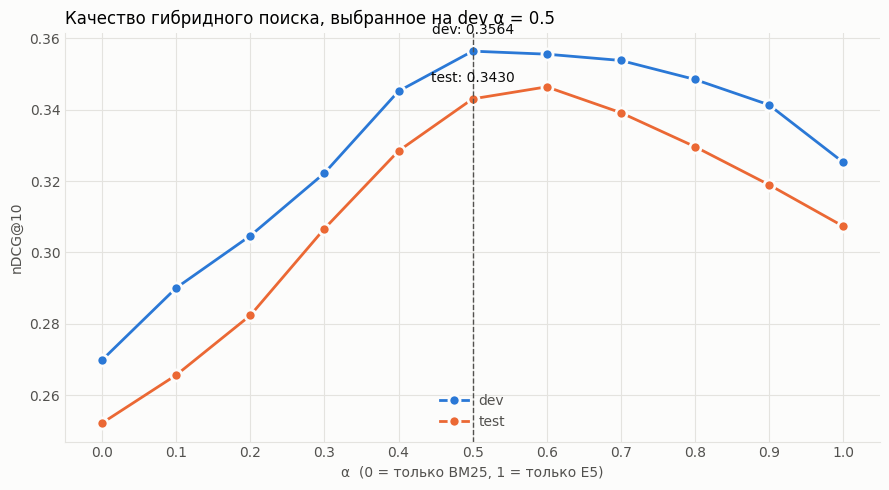

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

for color, (label, table) in zip(COLORS, (("dev", alpha_dev), ("test", alpha_test))):
    ax.plot(table.index, table["nDCG@10"], color=color, linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=label)
    value = table.loc[BEST_ALPHA, "nDCG@10"]
    ax.annotate(f"{label}: {value:.4f}", (BEST_ALPHA, value), textcoords="offset points",
                xytext=(0, 12), ha="center", color=INK, fontsize=10)

ax.axvline(BEST_ALPHA, color=INK_MUTED, linewidth=1, linestyle="--")
ax.set_xticks(ALPHAS)
ax.set_xlabel("α  (0 = только BM25, 1 = только E5)")
ax.set_ylabel("nDCG@10")
ax.set_title(f"Качество гибридного поиска, выбранное на dev α = {BEST_ALPHA}", loc="left")
ax.legend(frameon=False, loc="lower center", labelcolor=INK_MUTED)
style_axes(ax)
fig.tight_layout()
fig.savefig(RESULTS / "hybrid_alpha.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.6. Значимо ли преимущество гибрида

Разница средних сама по себе может оказаться случайной. Поэтому сравниваем методы на одних и тех же запросах test (парное сравнение) и бутстрепом оцениваем 95% доверительный интервал разности nDCG@10: 10 000 раз выбираем запросы с возвращением и пересчитываем среднюю разность. Если интервал не содержит ноль, преимущество устойчиво на этой выборке запросов.

In [22]:
def bootstrap_difference(a, b, n_resamples=10_000, seed=SEED):
    differences = (a - b).to_numpy()
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(differences), (n_resamples, len(differences)))
    means = differences[indices].mean(axis=1)
    return differences.mean(), *np.percentile(means, [2.5, 97.5])


hybrid_ndcg = metrics_test[BEST_ALPHA]["nDCG@10"]

comparison_rows = []
for name, alpha in (("BM25 (α = 0)", 0.0), ("E5 (α = 1)", 1.0)):
    delta, low, high = bootstrap_difference(hybrid_ndcg, metrics_test[alpha]["nDCG@10"])
    comparison_rows.append({
        "Сравнение": f"Гибрид α = {BEST_ALPHA} − {name}",
        "Разность nDCG@10": round(delta, 4),
        "95% ДИ, нижняя": round(low, 4),
        "95% ДИ, верхняя": round(high, 4),
        "Запросов лучше": int((hybrid_ndcg > metrics_test[alpha]["nDCG@10"]).sum()),
        "Запросов хуже": int((hybrid_ndcg < metrics_test[alpha]["nDCG@10"]).sum()),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(RESULTS / "hybrid_significance.csv", index=False)
display(comparison_df)

,Сравнение,Разность nDCG@10,"95% ДИ, нижняя","95% ДИ, верхняя",Запросов лучше,Запросов хуже
0,Гибрид α = 0.5 − BM25 (α = 0),0.0908,0.0753,0.1060,256,57
1,Гибрид α = 0.5 − E5 (α = 1),0.0356,0.0219,0.0504,186,118


### 5.7. Скорость полного гибридного запроса

В части 4 измерялся только плотный поиск. Здесь измеряем весь путь запроса по отдельным этапам на 200 запросах dev: кодирование моделью, плотный поиск, BM25 и фьюжн. Так видно, где тратится время и какая задержка будет в рабочем приложении.

In [23]:
stages = {"Кодирование E5": [], "Плотный поиск": [], "BM25": [], "Фьюжн": [], "Всего": []}

for q in dev_ids[:200]:
    text = query_text[q]

    t0 = time.perf_counter()
    vector = encode_queries([text])[0].tolist()
    t1 = time.perf_counter()
    dense = client.query_points(COLLECTION, query=vector, using="dense", limit=CANDIDATES,
                                search_params=SEARCH_PARAMS, with_payload=False).points
    t2 = time.perf_counter()
    bm25 = client.query_points(COLLECTION, query=bm25_document(text), using="bm25",
                               limit=CANDIDATES, with_payload=False).points
    t3 = time.perf_counter()
    fuse({p.id: p.score for p in dense}, {p.id: p.score for p in bm25}, BEST_ALPHA)
    t4 = time.perf_counter()

    stages["Кодирование E5"].append(t1 - t0)
    stages["Плотный поиск"].append(t2 - t1)
    stages["BM25"].append(t3 - t2)
    stages["Фьюжн"].append(t4 - t3)
    stages["Всего"].append(t4 - t0)

latency_df = pd.DataFrame({
    stage: {
        "среднее, мс": np.mean(values) * 1000,
        "p95, мс": np.percentile(values, 95) * 1000,
    }
    for stage, values in stages.items()
}).T.round(2)
latency_df.to_csv(RESULTS / "hybrid_latency.csv")
display(latency_df)

,"среднее, мс","p95, мс"
Кодирование E5,10.24,12.34
Плотный поиск,4.26,5.10
BM25,2.61,2.97
Фьюжн,0.16,0.20
Всего,17.26,19.94


### 5.8. Пример, где гибрид выигрывает

Чтобы увидеть механику на живом примере, находим запрос test, в котором гибрид опережает обе модели сильнее всего, и выводим первые три документа каждого метода. Один пример ничего не доказывает, а только иллюстрирует, как объединение списков поднимает нужный документ. Для общей оценки служат таблицы выше.

In [24]:
gain = hybrid_ndcg - metrics_test[0.0]["nDCG@10"].combine(metrics_test[1.0]["nDCG@10"], max)
example_id = gain.idxmax()
relevant = relevant_test[example_id]
doc_text = dict(zip(corpus["_id"], corpus["text"]))

print("Запрос:", query_text[example_id])
print(f"Прирост nDCG@10 относительно лучшей из двух моделей: {gain.max():.4f}")

for name, alpha in (("BM25", 0.0), ("E5", 1.0), (f"Гибрид α = {BEST_ALPHA}", BEST_ALPHA)):
    ranking = fuse(dense_test[example_id], bm25_test[example_id], alpha)
    print(f"\n{name} (nDCG@10 = {metrics_test[alpha].loc[example_id, 'nDCG@10']:.4f}):")
    for rank, doc_id in enumerate(ranking[:3], start=1):
        mark = "РЕЛЕВАНТЕН" if doc_id in relevant else "—"
        print(f"  {rank}. [{mark}] {doc_text[doc_id][:150]}")

Запрос: Why are we taxed on revenue and companies on profit?
Прирост nDCG@10 относительно лучшей из двух моделей: 0.5000

BM25 (nDCG@10 = 0.0000):
  1. [—] The company will have to pay 20% tax on its profits. Doesn't matter how these profits are earned. Profits = Income minus all money you spend to get th
  2. [—] It says Amazon has no profits (or very low profits) but the value of the company is very high and growing because of the high revenue. All of the retu
  3. [—] In principle, when you are the sole owner of a limited company, and also the sole employee, then it is much easier to assume that someone else is the 

E5 (nDCG@10 = 0.5000):
  1. [—] Enormous revenue, not profits. Profits would be taxed. Doesn't seem like a problem to me. You can't spend money without realizing the profits - it's w
  2. [—] Corporate profits are currently taxed twice. Once at the corporate level, and a second time when the corporation's owners get paid via dividends or ca
  3. [РЕЛЕВАНТЕН] "I pay taxe

## Остановка базы

Сервер продолжает работать в фоне и занимает оперативную память, пока его не остановить. Когда работа с ноутбуком закончена, раскомментируйте строку ниже. Данные останутся в `artifacts/qdrant/storage`, а `ensure_qdrant` при следующем запуске снова поднимет сервер.

In [ ]:
# stop_qdrant()